In [2]:
from data_loader import load_data

data = load_data()
data.keys()

P-54B (rt_actual_outages) [83/83 cached]: 100%|██████████| 83/83 [00:00<00:00, 1185.26zip/s]
P-511A (dam_limiting_constraints) [249/249 cached]: 100%|██████████| 249/249 [00:00<00:00, 4925.82zip/s]
P-27 (dam_bid_data) [474/474 cached]: 100%|██████████| 474/474 [00:00<00:00, 3006.43zip/s]


[CACHE HIT] Loading dam_lbmp_gen.parquet...
[CACHE HIT] Loading rt_int_lbmp_gen.parquet...
[CACHE HIT] Loading dam_lbmp_zone.parquet...
[CACHE HIT] Loading rt_int_lbmp_zone.parquet...
[CACHE HIT] Loading iso_load_forecast.parquet...
[CACHE HIT] Loading weather_forecast.parquet...
[CACHE HIT] Loading zonal_bid_load.parquet...
[CACHE HIT] Loading btm_solar_forecast.parquet...
[CACHE HIT] Loading rt_int_actual_load.parquet...
[CACHE HIT] Loading dam_sched_outages.parquet...
[CACHE HIT] Loading rt_actual_outages.parquet...
[CACHE HIT] Loading dam_limiting_constraints.parquet...
[CACHE HIT] Loading rt_fuel_mix.parquet...
[CACHE HIT] Loading interface_flows.parquet...
[CACHE HIT] Partitioned dataset ready at nyiso_data/merged_parquet/dam_bid_data/...
[CACHE HIT] Loading nodal_dart_spread.parquet & labels...
[CACHE HIT] Loading zonal_dart_spread.parquet & labels...
[CACHE HIT] Loading exogenous_features.parquet...

=== Pipeline Complete ===
Nodal DART Matrix:      (59958, 559) (Timestamps x G

dict_keys(['nodal_dart', 'nodal_labels', 'zonal_dart', 'zonal_labels', 'exog_features', 'dam_bids_dir', 'gen_meta', 'subzone_meta'])

,Model,Feature Set,Macro F1,Tail F1,Trades,Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Cum PnL ($),Annual Sharpe,Max DD ($)
0,Continuous Ridge Regression,Exog + 559 Nodes,0.3798,0.2384,6914,42.4,47.8,4.04,27963.84,3.50,4969.93
1,Causal 48h Persistence,Target Lags,0.4163,0.2547,5217,32.0,50.6,4.29,22388.24,2.31,6488.46
2,Galarneau-Vincent et al. (2023) GBDT,Exog + 559 Nodes,0.4502,0.3142,6812,41.8,58.1,3.48,23709.37,2.17,19928.86
3,Hubert et al. (2026) Multinomial Logit,Exog + 559 Nodes,0.3680,0.3041,11200,68.7,54.1,1.74,19539.42,1.78,18823.72
4,Hubert et al. (2026) Multinomial Logit,Exog-Only,0.3693,0.3060,11273,69.1,53.5,1.55,17509.44,1.59,16320.78
5,Hourly ARIMAX (24-hr),"Exog + AR(48,72,168)",0.3499,0.1238,1594,9.8,39.6,5.87,9355.99,1.25,11031.63
6,Galarneau-Vincent et al. (2023) GBDT,Exog-Only,0.4485,0.3053,6441,39.5,57.7,2.11,13602.31,1.24,26114.26
7,Reference LDA,Exog-Only,0.4060,0.2233,3943,24.2,55.8,2.56,10099.97,0.95,19076.51
8,Reference Balanced MLP,Exog-Only,0.3886,0.2615,7891,48.4,50.3,1.22,9634.38,0.90,24975.10


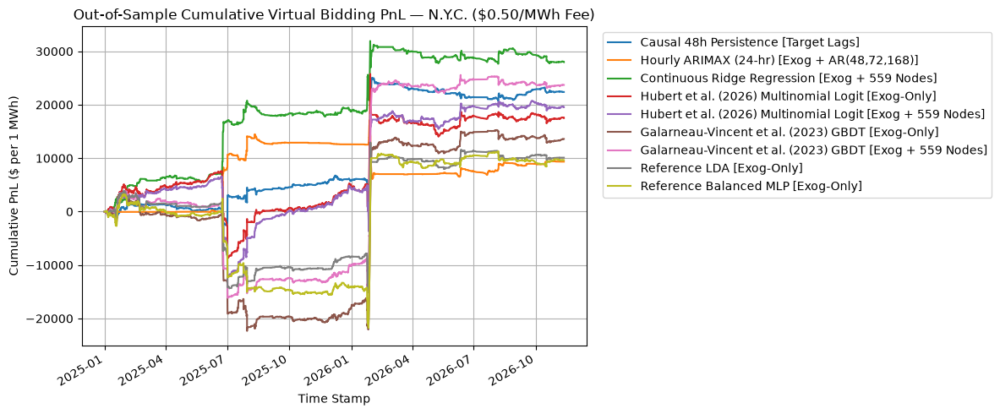

In [3]:
import matplotlib.pyplot as plt

from baseline import evaluate_baselines

# 2. Run the baseline & reference paper benchmark suite for N.Y.C.
baseline_results, baseline_pnl = evaluate_baselines(
    data=data,
    target_zone="N.Y.C.",
    train_end="2024-12-31 23:00:00",
    fee_per_mwh=0.50,
    # use_statsmodels_arimax=True,  # Uses 24 hourly SARIMAX models if statsmodels is installed
)

# 3. Display the sorted comparison table
display(
    baseline_results.sort_values(by="Annual Sharpe", ascending=False).reset_index(drop=True)
)

# 4. Plot cumulative out-of-sample PnL curves (2025–2026)
ax = baseline_pnl.cumsum().plot(
    figsize=(12, 5),
    title="Out-of-Sample Cumulative Virtual Bidding PnL — N.Y.C. ($0.50/MWh Fee)",
    ylabel="Cumulative PnL ($ per 1 MWh)",
    grid=True,
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


,Model,Feature Set,Macro F1,Tail F1,Trades,Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Cum PnL ($),Annual Sharpe,Max DD ($)
0,"Exact DMD (Mann & Kutz, 2015)",15 Zones + Delay Lags,0.3238,0.0899,1630,10.0,42.4,-3.70,-6023.68,-0.85,16383.75
1,"BOP-DMD (Sashidhar & Kutz, 2021)",15 Zones + Bagged VarPro,0.3187,0.0826,1589,9.7,42.3,-10.01,-15901.89,-2.28,25493.90


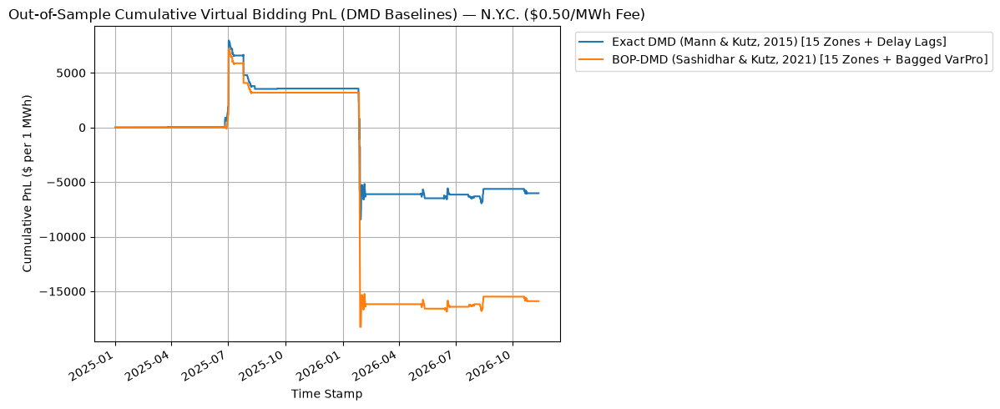

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

from dmd import evaluate_dmd_baselines

# 1. Run standalone Exact DMD & BOP-DMD baselines for N.Y.C.
dmd_results, dmd_pnl = evaluate_dmd_baselines(
    data=data,
    target_zone="N.Y.C.",
    train_end="2024-12-31 23:00:00",
    fee_per_mwh=0.50,
)

# 2. Display the sorted DMD comparison table
display(
    dmd_results.sort_values(by="Annual Sharpe", ascending=False).reset_index(drop=True)
)

# 3. Plot cumulative out-of-sample PnL curves (2025–2026)
ax = dmd_pnl.cumsum().plot(
    figsize=(12, 5),
    title="Out-of-Sample Cumulative Virtual Bidding PnL (DMD Baselines) — N.Y.C. ($0.50/MWh Fee)",
    ylabel="Cumulative PnL ($ per 1 MWh)",
    grid=True,
)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [5]:
import pandas as pd
from baseline import evaluate_baselines
from dmd import evaluate_dmd_baselines

# 1. Run standalone econometric & reference paper baselines (or reuse your cached results)
# baseline_results, baseline_pnl = evaluate_baselines(data=data, target_zone="N.Y.C.")

# 2. Run standalone Exact DMD & BOP-DMD baselines on the exact same test index
# dmd_results, dmd_pnl = evaluate_dmd_baselines(data=data, target_zone="N.Y.C.")

# 3. Combine into a unified comparison table & PnL DataFrame
all_baselines_df = (
    pd.concat([baseline_results, dmd_results], ignore_index=True)
    .sort_values(by="Annual Sharpe", ascending=False)
    .reset_index(drop=True)
)
all_baseline_pnl = pd.concat([baseline_pnl, dmd_pnl], axis=1)

display(all_baselines_df)


,Model,Feature Set,Macro F1,Tail F1,Trades,Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Cum PnL ($),Annual Sharpe,Max DD ($)
0,Continuous Ridge Regression,Exog + 559 Nodes,0.3798,0.2384,6914,42.4,47.8,4.04,27963.84,3.50,4969.93
1,Causal 48h Persistence,Target Lags,0.4163,0.2547,5217,32.0,50.6,4.29,22388.24,2.31,6488.46
2,Galarneau-Vincent et al. (2023) GBDT,Exog + 559 Nodes,0.4502,0.3142,6812,41.8,58.1,3.48,23709.37,2.17,19928.86
3,Hubert et al. (2026) Multinomial Logit,Exog + 559 Nodes,0.3680,0.3041,11200,68.7,54.1,1.74,19539.42,1.78,18823.72
4,Hubert et al. (2026) Multinomial Logit,Exog-Only,0.3693,0.3060,11273,69.1,53.5,1.55,17509.44,1.59,16320.78
5,Hourly ARIMAX (24-hr),"Exog + AR(48,72,168)",0.3499,0.1238,1594,9.8,39.6,5.87,9355.99,1.25,11031.63
6,Galarneau-Vincent et al. (2023) GBDT,Exog-Only,0.4485,0.3053,6441,39.5,57.7,2.11,13602.31,1.24,26114.26
7,Reference LDA,Exog-Only,0.4060,0.2233,3943,24.2,55.8,2.56,10099.97,0.95,19076.51
8,Reference Balanced MLP,Exog-Only,0.3886,0.2615,7891,48.4,50.3,1.22,9634.38,0.90,24975.10
9,"Exact DMD (Mann & Kutz, 2015)",15 Zones + Delay Lags,0.3238,0.0899,1630,10.0,42.4,-3.70,-6023.68,-0.85,16383.75


In [6]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

from baseline import compute_trading_metrics

# 1. Reconstruct the exact causal split from baseline.py
target_zone = "N.Y.C."
LAG_HOURS = 48
window_hours = 24 * 30
fee_per_mwh = 0.50

X_nodes_df = data["nodal_dart"].shift(LAG_HOURS).iloc[LAG_HOURS:]
X_exog_df = data["exog_features"].iloc[LAG_HOURS:].copy()
zonal_spread = data["zonal_dart"][target_zone].reindex(X_nodes_df.index)

X_exog_df["target_spread_lag48"] = zonal_spread.shift(48)
X_exog_df["target_spread_lag72"] = zonal_spread.shift(72)

shifted_spread = zonal_spread.shift(LAG_HOURS)
low_thresh = shifted_spread.rolling(window=window_hours, min_periods=24 * 7).quantile(0.15)
high_thresh = shifted_spread.rolling(window=window_hours, min_periods=24 * 7).quantile(0.85)

valid_mask = (
    low_thresh.notna()
    & high_thresh.notna()
    & zonal_spread.notna()
    & X_nodes_df.notna().all(axis=1)
    & X_exog_df["target_spread_lag72"].notna()
)

X_exog_df = X_exog_df.loc[valid_mask]
zonal_spread = zonal_spread.loc[valid_mask]
y_series = pd.Series(0, index=zonal_spread.index, dtype=int)
y_series[zonal_spread < low_thresh.loc[valid_mask]] = -1
y_series[zonal_spread > high_thresh.loc[valid_mask]] = 1

# Sub-split 2020–2024 into Train (2020–2023) & Val (2024) for leak-free tau tuning
sub_tr_mask = np.asarray(X_exog_df.index <= pd.Timestamp("2023-12-31 23:00:00"), dtype=bool)
val_mask = np.asarray(
    (X_exog_df.index > pd.Timestamp("2023-12-31 23:00:00"))
    & (X_exog_df.index <= pd.Timestamp("2024-12-31 23:00:00")),
    dtype=bool,
)
full_tr_mask = np.asarray(X_exog_df.index <= pd.Timestamp("2024-12-31 23:00:00"), dtype=bool)
test_mask = ~full_tr_mask

non_empty_cols = X_exog_df.columns[X_exog_df.loc[full_tr_mask].notna().any()]
X_raw = X_exog_df[non_empty_cols]

# Helper: apply Chow (1970) symmetric reject-option threshold tau
def apply_tau(probs: np.ndarray, classes: np.ndarray, tau: float) -> np.ndarray:
    idx_neg = int(np.where(classes == -1)[0][0])
    idx_pos = int(np.where(classes == 1)[0][0])
    p_neg, p_pos = probs[:, idx_neg], probs[:, idx_pos]
    preds = np.zeros(len(probs), dtype=int)
    preds[(p_pos > tau) & (p_pos > p_neg)] = 1
    preds[(p_neg > tau) & (p_neg > p_pos)] = -1
    return preds

# Fit preprocessing on 2020–2023 for tau tuning, and on 2020–2024 for final 2025–2026 test
imp_sub = SimpleImputer(strategy="median")
scl_sub = StandardScaler()
X_sub_tr = np.clip(scl_sub.fit_transform(imp_sub.fit_transform(X_raw.loc[sub_tr_mask])), -10.0, 10.0)
X_val = np.clip(scl_sub.transform(imp_sub.transform(X_raw.loc[val_mask])), -10.0, 10.0)
y_sub_tr = y_series.loc[sub_tr_mask].to_numpy()
spread_val = zonal_spread.loc[val_mask]

imp_full = SimpleImputer(strategy="median")
scl_full = StandardScaler()
X_full_tr = np.clip(scl_full.fit_transform(imp_full.fit_transform(X_raw.loc[full_tr_mask])), -10.0, 10.0)
X_test = np.clip(scl_full.transform(imp_full.transform(X_raw.loc[test_mask])), -10.0, 10.0)
y_full_tr = y_series.loc[full_tr_mask].to_numpy()
y_test = y_series.loc[test_mask].to_numpy()
spread_test = zonal_spread.loc[test_mask]

# Natural-prior models (no class_weight="balanced" so probabilities stay calibrated)
models_to_tune = {
    "Hubert et al. (2026) Logit (tau-tuned)": lambda: LogisticRegression(
        C=0.1, solver="lbfgs", max_iter=2000, tol=1e-3, random_state=42
    ),
    "Galarneau-Vincent et al. (2023) GBDT (tau-tuned)": lambda: HistGradientBoostingClassifier(
        max_depth=5, learning_rate=0.05, max_iter=200, random_state=42
    ),
    "Natural-Prior MLP (tau-tuned)": lambda: MLPClassifier(
        hidden_layer_sizes=(64, 32), alpha=1e-1, max_iter=200, random_state=42
    ),
}

tau_grid = np.arange(0.18, 0.42, 0.02)
new_records = []
new_pnl_curves = {}

for name, make_model in models_to_tune.items():
    # Step A: Tune tau on 2024 validation year (requiring >= 15% trade frequency so it doesn't overfit to 3 trades)
    m_val = make_model().fit(X_sub_tr, y_sub_tr)
    val_probs = m_val.predict_proba(X_val)
    best_tau, best_sharpe = 0.25, -np.inf

    for tau in tau_grid:
        val_preds = apply_tau(val_probs, m_val.classes_, tau)
        metrics = compute_trading_metrics(val_preds, spread_val, fee_per_mwh=fee_per_mwh)
        if metrics["Trade Freq (%)"] >= 15.0 and metrics["Annual Sharpe"] > best_sharpe:
            best_sharpe = metrics["Annual Sharpe"]
            best_tau = float(tau)

    # Step B: Refit on full 2020–2024 & evaluate fixed best_tau on 2025–2026
    m_full = make_model().fit(X_full_tr, y_full_tr)
    test_probs = m_full.predict_proba(X_test)
    test_preds = apply_tau(test_probs, m_full.classes_, best_tau)

    macro_f1 = f1_score(y_test, test_preds, average="macro", zero_division=0)
    tail_f1 = f1_score(y_test, test_preds, labels=[-1, 1], average="macro", zero_division=0)
    fin = compute_trading_metrics(test_preds, spread_test, fee_per_mwh=fee_per_mwh)

    new_records.append({
        "Model": f"{name} [tau={best_tau:.2f}]",
        "Feature Set": "Exog-Only",
        "Macro F1": round(float(macro_f1), 4),
        "Tail F1": round(float(tail_f1), 4),
        **fin,
    })
    new_pnl_curves[f"{name} [tau={best_tau:.2f}] (Exog-Only)"] = pd.Series(
        (test_preds * spread_test.to_numpy()) - (np.abs(test_preds) * fee_per_mwh),
        index=spread_test.index,
    )

# Mutate / append to existing baseline_results and baseline_pnl in place
baseline_results = (
    pd.concat([baseline_results, pd.DataFrame(new_records)], ignore_index=True)
    .drop_duplicates(subset=["Model", "Feature Set"], keep="last")
    .sort_values(by="Annual Sharpe", ascending=False)
    .reset_index(drop=True)
)
for col, s in new_pnl_curves.items():
    baseline_pnl[col] = s

display(baseline_results)


,Model,Feature Set,Macro F1,Tail F1,Trades,Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Cum PnL ($),Annual Sharpe,Max DD ($)
0,Continuous Ridge Regression,Exog + 559 Nodes,0.3798,0.2384,6914,42.4,47.8,4.04,27963.84,3.50,4969.93
1,Natural-Prior MLP (tau-tuned) [tau=0.24],Exog-Only,0.3899,0.2571,7601,46.6,53.9,3.64,27698.79,2.82,11120.52
2,Causal 48h Persistence,Target Lags,0.4163,0.2547,5217,32.0,50.6,4.29,22388.24,2.31,6488.46
3,Galarneau-Vincent et al. (2023) GBDT,Exog + 559 Nodes,0.4502,0.3142,6812,41.8,58.1,3.48,23709.37,2.17,19928.86
4,Hubert et al. (2026) Multinomial Logit,Exog + 559 Nodes,0.3680,0.3041,11200,68.7,54.1,1.74,19539.42,1.78,18823.72
5,Hubert et al. (2026) Logit (tau-tuned) [tau=0.18],Exog-Only,0.3805,0.3105,10943,67.1,53.6,1.74,19061.51,1.73,14894.24
6,Hubert et al. (2026) Multinomial Logit,Exog-Only,0.3693,0.3060,11273,69.1,53.5,1.55,17509.44,1.59,16320.78
7,Hourly ARIMAX (24-hr),"Exog + AR(48,72,168)",0.3499,0.1238,1594,9.8,39.6,5.87,9355.99,1.25,11031.63
8,Galarneau-Vincent et al. (2023) GBDT,Exog-Only,0.4485,0.3053,6441,39.5,57.7,2.11,13602.31,1.24,26114.26
9,Reference LDA,Exog-Only,0.4060,0.2233,3943,24.2,55.8,2.56,10099.97,0.95,19076.51


In [7]:
# In Notebook 1 (Baseline / SSPOC Evaluation):
baseline_results.to_parquet("nyiso_data/merged_parquet/stage1_baseline_results.parquet")
baseline_pnl.to_parquet("nyiso_data/merged_parquet/stage1_baseline_unit_pnl.parquet")


Reconstruct unit signals `signals_df` directly from your existing `baseline_pnl` DataFrame (`sign(pnl + 0.50)` is exact because fees are `$0.50/MWh` and nonzero spreads have magnitude > `$0.50`) and save to Parquet:

In [8]:
# Recover exact {-1, 0, +1} directional signals from unit-1 MWh PnL curves
spread_te = data["zonal_dart"]["N.Y.C."].reindex(baseline_pnl.index)
signals_df = pd.DataFrame(index=baseline_pnl.index)

for col in baseline_pnl.columns:
    pnl_vals = baseline_pnl[col].to_numpy()
    s_vals = spread_te.to_numpy()
    sig = np.zeros(len(pnl_vals), dtype=int)
    active = pnl_vals != 0.0
    # pnl = sig * spread - 0.50  =>  sig = round((pnl + 0.50) / spread)
    sig[active] = np.sign((pnl_vals[active] + 0.50) / np.where(s_vals[active] == 0, 1e-6, s_vals[active])).astype(int)
    signals_df[col] = sig

signals_df.to_parquet("nyiso_data/merged_parquet/stage1_signals.parquet")

In [9]:
import numpy as np
import pandas as pd

# 1. Block-bootstrap (24h blocks) 95% CI for Annual Sharpe & Win Rate
def block_bootstrap_sharpe(pnl_series: pd.Series, n_boot: int = 1000, block_len: int = 24):
    vals = pnl_series.to_numpy()
    n_blocks = len(vals) // block_len
    blocks = vals[: n_blocks * block_len].reshape(n_blocks, block_len)
    rng = np.random.default_rng(42)
    sharpes = []
    for _ in range(n_boot):
        sample = blocks[rng.integers(0, n_blocks, size=n_blocks)].ravel()
        sd = sample.std(ddof=1)
        sharpes.append((sample.mean() / sd) * np.sqrt(8760) if sd > 0 else 0.0)
    return np.percentile(sharpes, [2.5, 50.0, 97.5])

for col in baseline_pnl.columns:
    lo, med, hi = block_bootstrap_sharpe(baseline_pnl[col])
    print(f"{col:55s} | Sharpe 95% CI: [{lo:5.2f}, {hi:5.2f}] (median {med:5.2f})")


Causal 48h Persistence [Target Lags]                    | Sharpe 95% CI: [-0.90,  5.68] (median  2.16)
Hourly ARIMAX (24-hr) [Exog + AR(48,72,168)]            | Sharpe 95% CI: [-1.75,  3.33] (median  1.37)
Continuous Ridge Regression [Exog + 559 Nodes]          | Sharpe 95% CI: [ 0.33,  6.05] (median  3.43)
Hubert et al. (2026) Multinomial Logit [Exog-Only]      | Sharpe 95% CI: [-1.80,  5.79] (median  1.61)
Hubert et al. (2026) Multinomial Logit [Exog + 559 Nodes] | Sharpe 95% CI: [-1.56,  5.53] (median  1.67)
Galarneau-Vincent et al. (2023) GBDT [Exog-Only]        | Sharpe 95% CI: [-2.43,  5.40] (median  1.22)
Galarneau-Vincent et al. (2023) GBDT [Exog + 559 Nodes] | Sharpe 95% CI: [-1.72,  6.34] (median  2.15)
Reference LDA [Exog-Only]                               | Sharpe 95% CI: [-2.36,  5.35] (median  0.80)
Reference Balanced MLP [Exog-Only]                      | Sharpe 95% CI: [-2.71,  5.02] (median  0.80)
Hubert et al. (2026) Logit (tau-tuned) [tau=0.18] (Exog-Only) | Sharpe 

In [10]:
na_cols = data["exog_features"].columns[data["exog_features"].isna().any()].tolist()
print("Columns with NaNs:", na_cols)


Columns with NaNs: ['solar_fcst_CAPITL', 'solar_fcst_CENTRL', 'solar_fcst_DUNWOD', 'solar_fcst_GENESE', 'solar_fcst_HUD_VL', 'solar_fcst_LONGIL', 'solar_fcst_MHK_VL', 'solar_fcst_MILLWD', 'solar_fcst_NORTH', 'solar_fcst_NYC', 'solar_fcst_SYSTEM', 'solar_fcst_WEST', 'load_err_r7dm_CAPITL', 'load_err_r7dm_CENTRL', 'load_err_r7dm_DUNWOD', 'load_err_r7dm_GENESE', 'load_err_r7dm_HUD_VL', 'load_err_r7dm_LONGIL', 'load_err_r7dm_MHK_VL', 'load_err_r7dm_MILLWD', 'load_err_r7dm_NYC', 'load_err_r7dm_NORTH', 'load_err_r7dm_WEST', 'z_dart_r7dm_CAPITL', 'z_dart_r7dm_CENTRL', 'z_dart_r7dm_DUNWOD', 'z_dart_r7dm_GENESE', 'z_dart_r7dm_HUD_VL', 'z_dart_r7dm_H_Q', 'z_dart_r7dm_LONGIL', 'z_dart_r7dm_MHK_VL', 'z_dart_r7dm_MILLWD', 'z_dart_r7dm_NORTH', 'z_dart_r7dm_NPX', 'z_dart_r7dm_NYC', 'z_dart_r7dm_O_H', 'z_dart_r7dm_PJM', 'z_dart_r7dm_WEST', 'z_mcc_dart_r7dm_CAPITL', 'z_mcc_dart_r7dm_CENTRL', 'z_mcc_dart_r7dm_DUNWOD', 'z_mcc_dart_r7dm_GENESE', 'z_mcc_dart_r7dm_HUD_VL', 'z_mcc_dart_r7dm_H_Q', 'z_mcc_dart

In [11]:
import pandas as pd

pd.DataFrame(data['nodal_dart'])

PTID,23512,23513,23514,23515,23516,23517,23518,23519,23520,23522,...,345025,345026,345027,345028,345029,345030,345031,345032,345033,345034
Time Stamp,,,,,,,,,,,,,,,,,,,,,
2020-01-08 23:00:00,2.31,2.40,-3.21,2.36,2.38,2.46,2.38,2.36,2.31,2.62,...,1.96,1.95,2.14,2.45,-2.90,-2.92,-2.08,-3.52,-3.43,-2.89
2020-01-09 00:00:00,3.37,3.41,3.98,3.37,3.41,3.44,3.41,3.37,3.37,3.94,...,3.29,3.27,3.30,3.26,3.87,3.86,3.83,3.82,3.74,3.84
2020-01-09 01:00:00,4.08,4.10,5.04,4.07,4.11,4.12,4.11,4.08,4.09,4.50,...,4.02,3.99,4.02,3.98,4.86,4.90,4.78,4.86,4.76,4.89
2020-01-09 02:00:00,4.69,4.71,4.05,4.67,4.72,4.75,4.72,4.68,4.68,4.95,...,4.54,4.51,4.60,4.65,3.98,4.02,4.12,3.79,3.74,4.00
2020-01-09 03:00:00,4.07,4.11,2.99,4.07,4.12,4.17,4.12,4.08,4.09,4.32,...,3.91,3.89,3.98,4.05,2.94,2.97,3.13,2.75,2.73,2.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-11 07:00:00,-88.99,-87.40,-90.02,-87.04,-87.14,-87.14,-87.14,-87.10,-89.26,-85.58,...,-87.36,-86.57,-87.40,-87.85,-85.17,-87.33,-84.22,-85.06,-84.68,-87.22
2026-11-11 08:00:00,3.69,4.24,4.30,4.30,4.14,4.18,4.14,4.32,3.74,4.60,...,4.28,4.33,4.43,4.39,4.89,3.13,4.74,4.25,3.94,3.17
2026-11-11 09:00:00,2.12,2.45,2.74,2.50,2.41,2.47,2.41,2.54,2.21,3.05,...,2.60,2.67,2.72,2.66,3.28,1.98,3.21,2.73,2.41,2.00


In [12]:
from evaluate_models import plot_sspoc_sensors_map, run_zonal_dart_experiment

results_df, selectors, node_ptids = run_zonal_dart_experiment(data, target_zone="N.Y.C.")
chosen_sensors_df = plot_sspoc_sensors_map(data, selectors[20], node_ptids, target_zone="N.Y.C.")


/Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: St


=== Out-of-Sample Results for Target Zone: N.Y.C. ===
                Model  Sensors (p)  Macro F1  Tail F1 (-1 & +1)
      Exog-Only + LDA            0  0.414776           0.227615
      Exog-Only + MLP            0  0.398864           0.219394
          SSPOC + LDA            5  0.419782           0.234707
SSPOC + MLPClassifier            5  0.420887           0.277025
          SSPOC + LDA           10  0.419676           0.234251
SSPOC + MLPClassifier           10  0.428564           0.280573
          SSPOC + LDA           20  0.420377           0.234986
SSPOC + MLPClassifier           20  0.416182           0.256588
          SSPOC + LDA           40  0.417771           0.231577
SSPOC + MLPClassifier           40  0.411126           0.255521
  All-559-Nodes + LDA          559  0.422591           0.240054
  All-559-Nodes + MLP          559  0.410657           0.230891

=== Top 20 SSPOC Sensor Nodes for N.Y.C. ===
PTID_str       Generator Name   Zone           Subzone  Sensor Weig

In [13]:
from evaluate_models import plot_sspoc_sensors_with_interconnects

chosen_sensors_df = plot_sspoc_sensors_with_interconnects(data, selectors[20], node_ptids, target_zone="N.Y.C.")
chosen_sensors_df.head()

,Generator Name,Generator PTID,Aggregation PTID,Subzone,Zone,Latitude,Longitude,Active,PTID_str,Sensor Weight
666,PJM_GEN_KEYSTONE,24065,NaN,PJM-AC,PJM,NaN,NaN,Y,24065,1.079383
744,SHOEMAKER___GT,23640,NaN,O&R HUDSON VLY,HUD VL,41.428457,-74.417580,Y,23640,0.982201
752,SITHE___BATAVIA,24024,NaN,NMPC GENESEE,GENESE,42.982493,-78.159298,Y,24024,0.908201
597,OCC_CHEM___DRP,24175,NaN,NMPC WEST,WEST,43.098460,-79.007149,Y,24175,0.797887
531,NEG CENTRAL___INDECK,23768,NaN,NYSEG CENTRAL,CENTRL,42.701493,-77.996815,Y,23768,0.781319


In [14]:
data['nodal_dart']

PTID,23512,23513,23514,23515,23516,23517,23518,23519,23520,23522,...,345025,345026,345027,345028,345029,345030,345031,345032,345033,345034
Time Stamp,,,,,,,,,,,,,,,,,,,,,
2020-01-08 23:00:00,2.31,2.40,-3.21,2.36,2.38,2.46,2.38,2.36,2.31,2.62,...,1.96,1.95,2.14,2.45,-2.90,-2.92,-2.08,-3.52,-3.43,-2.89
2020-01-09 00:00:00,3.37,3.41,3.98,3.37,3.41,3.44,3.41,3.37,3.37,3.94,...,3.29,3.27,3.30,3.26,3.87,3.86,3.83,3.82,3.74,3.84
2020-01-09 01:00:00,4.08,4.10,5.04,4.07,4.11,4.12,4.11,4.08,4.09,4.50,...,4.02,3.99,4.02,3.98,4.86,4.90,4.78,4.86,4.76,4.89
2020-01-09 02:00:00,4.69,4.71,4.05,4.67,4.72,4.75,4.72,4.68,4.68,4.95,...,4.54,4.51,4.60,4.65,3.98,4.02,4.12,3.79,3.74,4.00
2020-01-09 03:00:00,4.07,4.11,2.99,4.07,4.12,4.17,4.12,4.08,4.09,4.32,...,3.91,3.89,3.98,4.05,2.94,2.97,3.13,2.75,2.73,2.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-11 07:00:00,-88.99,-87.40,-90.02,-87.04,-87.14,-87.14,-87.14,-87.10,-89.26,-85.58,...,-87.36,-86.57,-87.40,-87.85,-85.17,-87.33,-84.22,-85.06,-84.68,-87.22
2026-11-11 08:00:00,3.69,4.24,4.30,4.30,4.14,4.18,4.14,4.32,3.74,4.60,...,4.28,4.33,4.43,4.39,4.89,3.13,4.74,4.25,3.94,3.17
2026-11-11 09:00:00,2.12,2.45,2.74,2.50,2.41,2.47,2.41,2.54,2.21,3.05,...,2.60,2.67,2.72,2.66,3.28,1.98,3.21,2.73,2.41,2.00


In [15]:
nan_cols = data["exog_features"].isna().sum()
print(nan_cols[nan_cols > 0])


solar_fcst_CAPITL         7464
solar_fcst_CENTRL         7464
solar_fcst_DUNWOD         7464
solar_fcst_GENESE         7464
solar_fcst_HUD_VL         7464
solar_fcst_LONGIL         7464
solar_fcst_MHK_VL         7464
solar_fcst_MILLWD         7464
solar_fcst_NORTH          7464
solar_fcst_NYC            7464
solar_fcst_SYSTEM         7464
solar_fcst_WEST           7464
load_err_r7dm_CAPITL        23
load_err_r7dm_CENTRL        23
load_err_r7dm_DUNWOD        23
load_err_r7dm_GENESE        23
load_err_r7dm_HUD_VL        23
load_err_r7dm_LONGIL        23
load_err_r7dm_MHK_VL        23
load_err_r7dm_MILLWD        23
load_err_r7dm_NYC           23
load_err_r7dm_NORTH         23
load_err_r7dm_WEST          23
z_dart_r7dm_CAPITL          23
z_dart_r7dm_CENTRL          23
z_dart_r7dm_DUNWOD          23
z_dart_r7dm_GENESE          23
z_dart_r7dm_HUD_VL          23
z_dart_r7dm_H_Q             23
z_dart_r7dm_LONGIL          23
z_dart_r7dm_MHK_VL          23
z_dart_r7dm_MILLWD          23
z_dart_r

In [16]:
import plotly.express as px
from backtest import evaluate_model_suite

results_df, pnl_curves_df, selectors = evaluate_model_suite(
    data,
    target_zone="N.Y.C.",
    sensor_budgets=[5, 10, 20, 40],
    fee_per_mwh=0.50,  # $0.50/MWh NYISO virtual transaction & collateral hurdle
)

print("=== Out-of-Sample Statistical & Financial Results (2025-2026) ===")
print(results_df.to_string(index=False))

# Plot Cumulative Out-of-Sample Equity Curves
cum_pnl_df = pnl_curves_df.cumsum()
fig = px.line(
    cum_pnl_df,
    title="Out-of-Sample Virtual Trading Cumulative PnL (1 MWh/hr, Net of $0.50/MWh Fees)",
    labels={"value": "Cumulative PnL ($)", "variable": "Strategy"},
)
fig.show()


/Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


=== Out-of-Sample Statistical & Financial Results (2025-2026) ===
                      Model  Sensors (p)  Macro F1  Tail F1  Trades  Trade Freq (%)  Win Rate (%)  Avg PnL/Trade ($)  Cum PnL ($)  Annual Sharpe  Max DD ($)
     Causal 48h Persistence            0    0.4163   0.2547    5217            32.0          50.6               4.29     22388.24           2.31     6488.46
Continuous Ridge Regression          559    0.3754   0.2352    7126            43.7          46.4               3.44     24532.43           2.93     5053.02
            Exog-Only + LDA            0    0.4078   0.2250    3815            23.4          57.7               3.92     14958.27           1.41    23053.89
            Exog-Only + MLP            0    0.3946   0.2369    5510            33.8          53.5               3.90     21498.98           2.36    12908.43
                SSPOC + LDA            5    0.4085   0.2262    3833            23.5          57.6               4.06     15546.56           1.46    2